# Part 4 — CNN Classification
Balance via Part 2 · Train CNN · Evaluate with f1-score

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import re

# silent warnings
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report

from src.augmentation import balance_dataset
from src.data import CLASSES, DATA_PATH, resolve_images
from src.model import (
    evaluate,
    save_model,
    train,
    zip_artifacts,
)

warnings.filterwarnings("ignore", category=UserWarning, module="tensorflow")

I0000 00:00:1787730699.742963   64377 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787730699.746021   64377 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787730700.089320   64377 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787730702.423653   64377 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## 1. Balance dataset (Part 2) → augmented_directory

In [2]:
data = resolve_images(DATA_PATH, CLASSES)
counts = {k: len(v) for k, v in data.items()}
max_len = max(counts.values())
print("Before:", counts)

out_dir = Path.cwd().parent / "augmented_directory"
balance_dataset(data, max_len=max_len, out_dir=str(out_dir))

after = {
    d.name: len(list(d.glob("*"))) for d in sorted(out_dir.iterdir()) if d.is_dir()
}
print("After:", after)

Before: {'Apple_Black_rot': 620, 'Apple_healthy': 1646, 'Apple_rust': 275, 'Apple_scab': 629, 'Grape_Black_rot': 1178, 'Grape_Esca': 1382, 'Grape_healthy': 422, 'Grape_spot': 1075}
After: {'Apple_Black_rot': 1646, 'Apple_healthy': 1646, 'Apple_rust': 1646, 'Apple_scab': 1646, 'Grape_Black_rot': 1646, 'Grape_Esca': 1646, 'Grape_healthy': 1646, 'Grape_spot': 1646}


## 2. Train CNN

In [3]:
model, history, train_ds, val_ds, class_names = train(
    train_dir=str(Path.cwd().parent / "augmented_directory"),
    epochs=100,
    target_acc=0.90,
    patience=10,
)

Found 13168 files belonging to 8 classes.
Using 10535 files for training.
Using 2633 files for validation.


E0000 00:00:1787730715.053004   64377 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1787730715.053542   64978 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1787730715.070994   64377 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Classes (8): ['Apple_Black_rot', 'Apple_healthy', 'Apple_rust', 'Apple_scab', 'Grape_Black_rot', 'Grape_Esca', 'Grape_healthy', 'Grape_spot']
Epoch 1/100


/home/samy/Leaffliction/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.8673 - loss: 0.3849
Per-class F1: Apple_Black_rot=0.943, Apple_healthy=0.973, Apple_rust=0.989, Apple_scab=0.934, Grape_Black_rot=0.777, Grape_Esca=0.842, Grape_healthy=0.957, Grape_spot=0.961
Worst class: Grape_Black_rot (0.7770)
330/330 ━━━━━━━━━━━━━━━━━━━━ 82s 240ms/step - accuracy: 0.8673 - loss: 0.3849 - val_accuracy: 0.9233 - val_loss: 0.1976 - val_f1_Apple_Black_rot: 0.9435 - val_f1_Apple_healthy: 0.9730 - val_f1_Apple_rust: 0.9892 - val_f1_Apple_scab: 0.9337 - val_f1_Grape_Black_rot: 0.7770 - val_f1_Grape_Esca: 0.8423 - val_f1_Grape_healthy: 0.9571 - val_f1_Grape_spot: 0.9613
Epoch 2/100
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.9374 - loss: 0.1624
Per-class F1: Apple_Black_rot=0.960, Apple_healthy=0.961, Apple_rust=0.988, Apple_scab=0.950, Grape_Black_rot=0.893, Grape_Esca=0.901, Grape_healthy=0.986, Grape_spot=0.983
Worst class: Grape_Black_rot (0.8934)
330/330 ━━━━━━━━━━━━━━━━━━━━ 88s 268ms/step - accura

## 3. Evaluate — accuracy + f1-score per class

In [4]:
acc, y_true, y_pred, cm = evaluate(model, val_ds, class_names)

83/83 ━━━━━━━━━━━━━━━━━━━━ 13s 161ms/step

Accuracy: 0.9635  (target: >95%)

                 precision    recall  f1-score   support

Apple_Black_rot       0.98      0.98      0.98       320
  Apple_healthy       0.98      0.96      0.97       317
     Apple_rust       0.99      1.00      1.00       324
     Apple_scab       0.96      0.97      0.97       320
Grape_Black_rot       0.92      0.90      0.91       355
     Grape_Esca       0.91      0.92      0.92       311
  Grape_healthy       0.99      0.99      0.99       358
     Grape_spot       0.97      0.99      0.98       328

       accuracy                           0.96      2633
      macro avg       0.96      0.96      0.96      2633
   weighted avg       0.96      0.96      0.96      2633



## 4. Save model + zip

In [5]:
save_model(model, class_names, out_dir=str(Path.cwd().parent / "model"))
zip_path = zip_artifacts(
    train_dir=str(Path.cwd().parent / "augmented_directory"),
    model_dir=str(Path.cwd().parent / "model"),
    out_zip=str(Path.cwd().parent / "model.zip"),
)
print(f"\nDone: {zip_path}")

Model saved to /home/samy/Leaffliction/model
Zipped → /home/samy/Leaffliction/model.zip

Done: /home/samy/Leaffliction/model.zip


## 5. Evaluate on test images (test/Unit_test1 & test/Unit_test2)

In [6]:
test_dirs = [Path.cwd().parent / "test" / d for d in ["Unit_test1", "Unit_test2"]]
test_files = sorted(f for d in test_dirs if d.exists() for f in d.glob("*.JPG"))
print(f"Found {len(test_files)} test images\n")

true_labels, pred_labels, probs_list, filenames = [], [], [], []

for img_path in test_files:
    # extract true label from filename: Apple_healthy1.JPG → Apple_healthy
    true = re.sub(r"(\d+)?\.JPG$", "", img_path.name)
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # img_resized = cv2.resize(img, (64, 64))
    img_resized = cv2.resize(img, (96, 96))
    prob = tf.nn.softmax(
        model.predict(img_resized[np.newaxis, ...], verbose=0)
    ).numpy()[0]
    pred = class_names[np.argmax(prob)]

    true_labels.append(true)
    pred_labels.append(pred)
    probs_list.append(prob)
    filenames.append(img_path.name)

acc = sum(t == p for t, p in zip(true_labels, pred_labels)) / len(true_labels)
print(
    f"Test accuracy: {acc:.2%}  ({sum(t == p for t, p in zip(true_labels, pred_labels))}/{len(true_labels)})"
)

print("\n" + classification_report(true_labels, pred_labels, zero_division=0))

print("Details:")
for fn, true, pred in zip(filenames, true_labels, pred_labels):
    mark = "OK" if true == pred else "WRONG"
    print(f"  [{mark:5s}] {fn:30s}  true={true:25s}  pred={pred}")

Found 10 test images

Test accuracy: 100.00%  (10/10)

                 precision    recall  f1-score   support

Apple_Black_rot       1.00      1.00      1.00         1
  Apple_healthy       1.00      1.00      1.00         2
     Apple_rust       1.00      1.00      1.00         1
     Apple_scab       1.00      1.00      1.00         1
Grape_Black_rot       1.00      1.00      1.00         2
     Grape_Esca       1.00      1.00      1.00         1
  Grape_healthy       1.00      1.00      1.00         1
     Grape_spot       1.00      1.00      1.00         1

       accuracy                           1.00        10
      macro avg       1.00      1.00      1.00        10
   weighted avg       1.00      1.00      1.00        10

Details:
  [OK   ] Apple_Black_rot1.JPG            true=Apple_Black_rot            pred=Apple_Black_rot
  [OK   ] Apple_healthy1.JPG              true=Apple_healthy              pred=Apple_healthy
  [OK   ] Apple_healthy2.JPG              true=Apple_healthy 

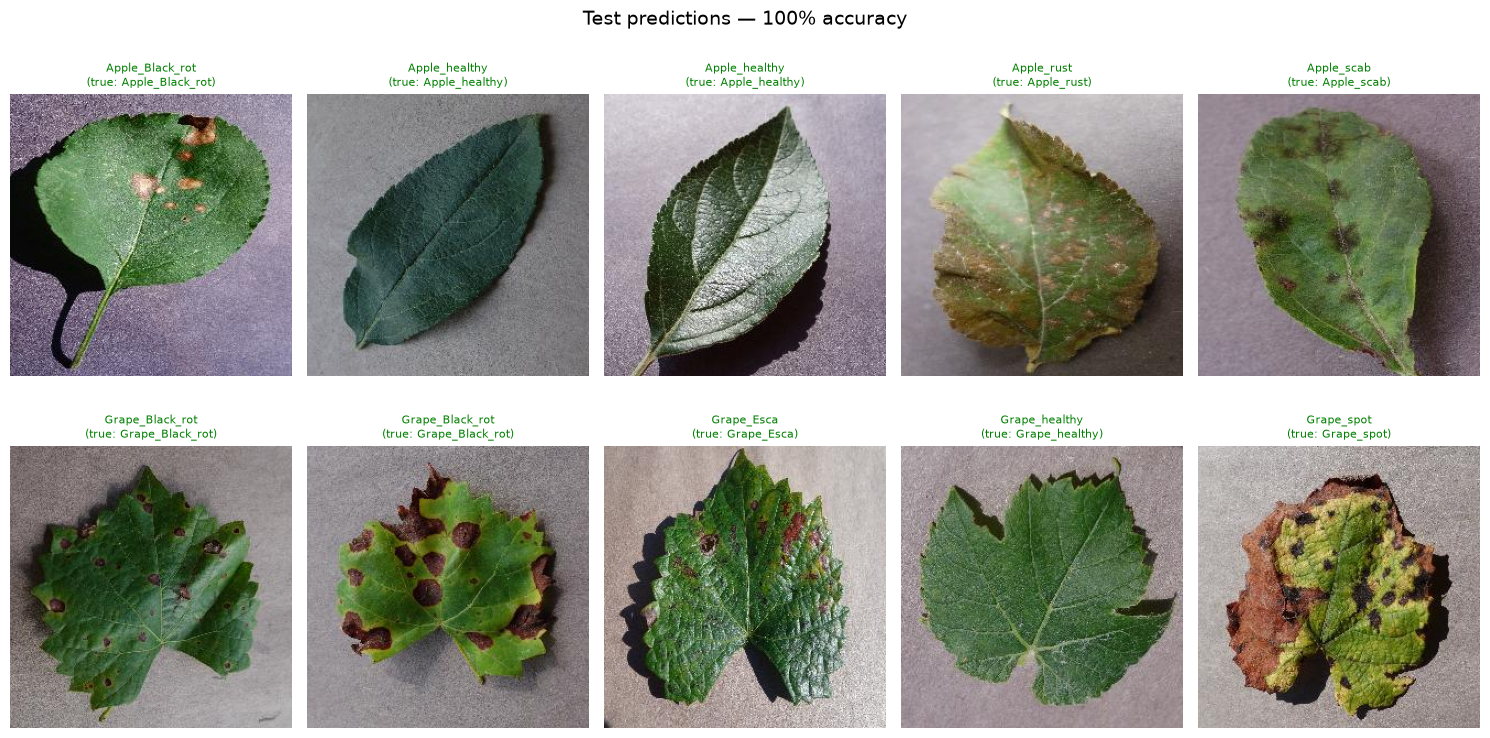

In [7]:
cols = 5
rows = (len(test_files) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 4))
axes = axes.flatten()

for i, (img_path, prob, true, pred) in enumerate(
    zip(test_files, probs_list, true_labels, pred_labels)
):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    color = "green" if true == pred else "red"
    axes[i].imshow(img)
    axes[i].set_title(f"{pred}\n(true: {true})", fontsize=8, color=color)
    axes[i].axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle(f"Test predictions — {acc:.0%} accuracy", fontsize=14)
plt.tight_layout()
plt.show()